**INSTALACIÓN E IMPORTACIÓN DE LIBRERÍAS**

In [2]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [1]:
%pip install geopandas

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install folium
#FOLIUM CREA MAPAS INTERACTIVOS EN FORMATO HTML (WEB)

Note: you may need to restart the kernel to use updated packages.


In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy.spatial.distance import pdist, squareform #calcula distancias entre todos los pares de puntos de un conjunto de datos

In [2]:
import folium
from folium import LayerControl # agrega o quita las capas de información
from folium.plugins import MarkerCluster #agrupan puntos en burbujas

In [8]:
from pathlib import Path
BASE = Path(r"C:\Users\esper\anaconda_projects\datos proyecto ciencia de datos")


In [9]:
def buscar_archivo(nombre):
    archivos = list(BASE.rglob(nombre))

    if len(archivos) == 0:
        raise FileNotFoundError(f"No se encontró: {nombre}")

    return archivos[0]

**MUNICIPIOS**

In [11]:
municipios = gpd.read_file(
    buscar_archivo("sig_municipios.shp")
)

print(municipios.head(10))

   GID MUNICIPIO                                              SERIE  \
0   41         A  BXA, BXC, BXB, BVC, BTA, BTC, BVB, BVA, BUB, B...   
1   42         B  AAA, ACA, AKA, AIA, AMA, APA, ARA, ASA, ATA, A...   
2   43         C  BPA, BPC, BGA, BQA, BQB, BNA, BMA, BMB, BKA, B...   
3   44        CH        ATB, AUA, AUB, AZA, BAB, BAA, AZB, AXA, AXB   
4   45         D        BOA, BOB, BDD, BNC, BNB, BBC, BBD, BBB, BBA   
5   46         E                  BCE, BCB, BCG, BCF, BCA, BCC, BCD   
6   47         F                            BDA, BDB, BDC, BDE, BDF   
7   48         G                      BZA, BZB, BZC, BRA, BRB, BRC.   

                                             LIMITES   AREA_HA  \
0  Arroyo Miguelete, Carlos M. de Pena, Camino Le...  14380.00   
1  Rio de la Plata, Bulevar General Artigas, Mont...   1147.59   
2  Bahia, Arroyo Miguelete, Bvr. Jose Batlle y Or...   1742.32   
3  Rio de la Plata, Bvr. Jose Batlle y Ordo?ez, A...   1194.85   
4  Arroyo Miguelete, Limite De

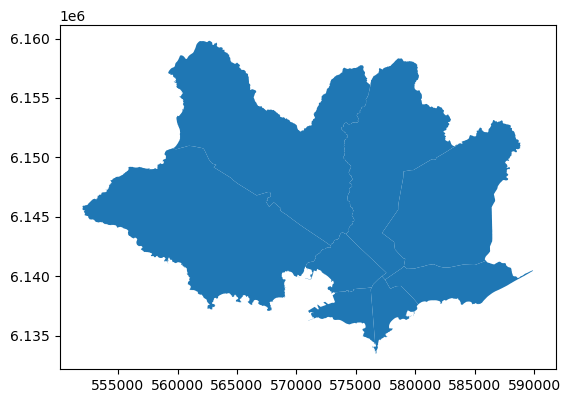

In [12]:
municipios.plot()

plt.show()

**CARGA DE DATOS**

In [14]:
educacion = pd.read_csv(
    buscar_archivo("uptu_educacion.csv"),
    sep=";"
)

print(educacion.head())

policlinicas = pd.read_csv(
    buscar_archivo("ubicacion-de-las-policlinicas-de-la-intendencia-de-montevideo.csv"),
    sep=","
)

salud = pd.read_csv(
    buscar_archivo("uptu_salud.csv"),
    sep=";"
)

print(policlinicas.head())

print(salud.head())

prox_paradas = gpd.read_file(
    buscar_archivo("proximidadparadas.gpkg")
)

paradas = gpd.read_file(
    buscar_archivo("v_uptu_paradas.shp")
)

recorrido_omnibus = gpd.read_file(
    buscar_archivo("v_uptu_lsv.shp")
)

print("-----------------------------")

print(prox_paradas.head())

print("-----------------------------")

print(paradas.head())

print("-----------------------------")

   codigo                           nombre             direccion  \
0     939                COLEGIO ATAHUALPA                   NaN   
1    1546  JARDIN DE INFANTES 105 COLORES                    NaN   
2    1640                         LICEO 46                   NaN   
3     840          CENTRO CAIF ARCA DE NOE  AV JOSE BELLONI 6121   
4     842                 CENTRO CAIF AZUL         MERCEDES 1228   

               x             y  
0  573930.248940  6.141899e+06  
1  581770.000000  6.138977e+06  
2  568148.013144  6.144049e+06  
3  579032.386450  6.150214e+06  
4  574007.045969  6.137308e+06  
      Policlínica                                 Dirección  Región  \
0      Barrio Sur                  Av. Gonzalo Ramírez 1270  Centro   
1  Luisa Tiraparé                          Av. Uruguay 1936  Centro   
2           Buceo                   Av. Santiago Rivas 1500  Centro   
3    Irma Gentile  Altamirano y Av. Luis Alberto de Herrera  Centro   
4      Crottogini                     

In [15]:
#IDENTIFICAR COLUMNAS DE DATOS
print("EDUCACION:", educacion.columns.tolist())
print("SALUD:", salud.columns.tolist())
print("POLICLINICAS:", policlinicas.columns.tolist())
print("PARADAS:", paradas.columns.tolist())
print("PROX. PARADAS:", prox_paradas.columns.tolist())
print("REC. OMNIBUS:", recorrido_omnibus.columns.tolist())


EDUCACION: ['codigo', 'nombre', 'direccion', 'x', 'y']
SALUD: ['codigo', 'nombre', 'direccion', 'x', 'y']
POLICLINICAS: ['Policlínica', 'Dirección', 'Región', 'Latitud', 'Longitud']
PARADAS: ['COD_UBIC_P', 'DESC_LINEA', 'COD_VARIAN', 'ORDINAL', 'CALLE', 'ESQUINA', 'COD_CALLE1', 'COD_CALLE2', 'X', 'Y', 'geometry']
PROX. PARADAS: ['CODCOMP_A', 'DistanciaParada_mean', 'P_TOT_Parada300m', 'P_TOT_HOM_Parada300m', 'P_TOT_MUJ_Parada300m', 'geometry']
REC. OMNIBUS: ['GID', 'COD_LINEA', 'DESC_LINEA', 'ORDINAL_SU', 'COD_SUBLIN', 'DESC_SUBLI', 'COD_VARIAN', 'DESC_VARIA', 'geometry']


In [17]:
#POBLACIÓN POR MUNICIPIO
poblacion = pd.read_excel(
    r"C:\Users\esper\anaconda_projects\datos proyecto ciencia de datos\Info sobre población\Población Municipios.xlsx"
)

print(poblacion.head())

  Municipio  Población  Policlínicas
0         A     206236             7
1         D     173170             4
2         G     153928             3
3         B     149350             2
4         C     141785             2


In [18]:
poblacion = poblacion.rename(columns={
    "Municipio": "MUNICIPIO",
    "Población": "poblacion"
})

In [19]:
print(municipios.columns)

Index(['GID', 'MUNICIPIO', 'SERIE', 'LIMITES', 'AREA_HA', 'FCREA', 'UCREA',
       'FACT', 'UACT', 'IDAUDITORI', 'geometry'],
      dtype='object')


In [20]:
municipios["area_km2"] = municipios.geometry.area / 1_000_000

In [22]:
print(municipios.columns)

Index(['GID', 'MUNICIPIO', 'SERIE', 'LIMITES', 'AREA_HA', 'FCREA', 'UCREA',
       'FACT', 'UACT', 'IDAUDITORI', 'geometry', 'area_km2'],
      dtype='object')


In [23]:
# Cargar Excel
poblacion = pd.read_excel(
    buscar_archivo("Población Municipios.xlsx")
)

# Renombrar columnas
poblacion = poblacion.rename(columns={
    "Municipio": "MUNICIPIO",
    "Población": "poblacion"
})

# Unir con municipios
municipios = municipios.merge(
    poblacion[["MUNICIPIO", "poblacion"]],
    on="MUNICIPIO",
    how="left"
)

In [24]:
print(municipios[["MUNICIPIO", "poblacion"]])

  MUNICIPIO  poblacion
0         A     206236
1         B     149350
2         C     141785
3        CH     157410
4         D     173170
5         E     145492
6         F     173991
7         G     153928


In [25]:
municipios["habitantes_por_km2"] = (
    municipios["poblacion"] / municipios["area_km2"]
)

In [26]:
print(
    municipios[
        ["MUNICIPIO", "poblacion", "area_km2", "habitantes_por_km2"]
    ]
)

  MUNICIPIO  poblacion    area_km2  habitantes_por_km2
0         A     206236  143.446004         1437.725659
1         B     149350   11.933127        12515.579450
2         C     141785   17.988351         7882.045286
3        CH     157410   11.995715        13122.186145
4         D     173170   86.157967         2009.912794
5         E     145492   26.881712         5412.304078
6         F     173991   85.134877         2043.710011
7         G     153928  143.070302         1075.890651


In [27]:
print(municipios.crs)

EPSG:32721


In [28]:
municipios_m = municipios.to_crs(epsg=32721)

In [29]:
municipios_m["area_km2"] = (
    municipios_m.geometry.area / 1_000_000
)

In [30]:
municipios_m["habitantes_por_km2"] = (
    municipios_m["poblacion"] / municipios_m["area_km2"]
)

In [31]:
print(
    municipios_m[
        ["MUNICIPIO", "poblacion", "area_km2", "habitantes_por_km2"]
    ]
)

  MUNICIPIO  poblacion    area_km2  habitantes_por_km2
0         A     206236  143.446004         1437.725659
1         B     149350   11.933127        12515.579450
2         C     141785   17.988351         7882.045286
3        CH     157410   11.995715        13122.186145
4         D     173170   86.157967         2009.912794
5         E     145492   26.881712         5412.304078
6         F     173991   85.134877         2043.710011
7         G     153928  143.070302         1075.890651


In [32]:
print(municipios[["MUNICIPIO", "AREA_HA"]])

  MUNICIPIO   AREA_HA
0         A  14380.00
1         B   1147.59
2         C   1742.32
3        CH   1194.85
4         D   8603.33
5         E   2683.40
6         F   8514.36
7         G  14240.00


In [33]:
municipios["area_km2"] = municipios["AREA_HA"] / 100
municipios["habitantes_por_km2"] = (
    municipios["poblacion"] / municipios["area_km2"]
)
municipios["habitantes_por_km2"] = municipios["habitantes_por_km2"].round(0)
print(
    municipios[
        ["MUNICIPIO", "poblacion", "area_km2", "habitantes_por_km2"]
    ]
)

  MUNICIPIO  poblacion  area_km2  habitantes_por_km2
0         A     206236  143.8000              1434.0
1         B     149350   11.4759             13014.0
2         C     141785   17.4232              8138.0
3        CH     157410   11.9485             13174.0
4         D     173170   86.0333              2013.0
5         E     145492   26.8340              5422.0
6         F     173991   85.1436              2044.0
7         G     153928  142.4000              1081.0


**MAPA CON DATOS INTEGRADOS**

In [34]:
#PASAR TODO A TARGET_CRS PARA TENER TODOS LOS DATOS EN EL MISMO MARCO DE COORDENADAS PARA USAR FOLIUM
TARGET_CRS = "EPSG:4326"
gdf_educacion = gpd.GeoDataFrame(
    educacion, 
    geometry=gpd.points_from_xy(educacion['x'], educacion['y']), 
    crs="EPSG:32721"
).to_crs(TARGET_CRS)

gdf_salud = gpd.GeoDataFrame(
    salud, 
    geometry=gpd.points_from_xy(salud['x'], salud['y']), 
    crs="EPSG:32721"
).to_crs(TARGET_CRS)

gdf_policlinicas = gpd.GeoDataFrame(
    policlinicas, 
    geometry=gpd.points_from_xy(policlinicas['Longitud'], policlinicas['Latitud']), 
    crs="EPSG:4326"
)

municipios = municipios.to_crs(TARGET_CRS)         
paradas = paradas.to_crs(TARGET_CRS)
recorrido_omnibus = recorrido_omnibus.to_crs(TARGET_CRS)
prox_paradas = prox_paradas.to_crs(TARGET_CRS)

In [36]:
# Centrar el mapa en Montevideo
m = folium.Map(location=[-34.88, -56.16], zoom_start=12, tiles="cartodbdark_matter")

# 1. Capa base: Municipios + datos de población
folium.GeoJson(
    municipios,
    name="Municipios",
    style_function=lambda x: {
        "fillColor": "transparent",
        "color": "white",
        "weight": 2
    },
    tooltip=folium.GeoJsonTooltip(
        fields=[
            "MUNICIPIO",
            "poblacion",
            "area_km2",
            "habitantes_por_km2"
        ],
        aliases=[
            "Municipio:",
            "Población:",
            "Área (km²):",
            "Densidad (hab/km²):"
        ],
        localize=True,
        sticky=False
    )
).add_to(m)

# 2. Capa: Recorrido de Ómnibus (Líneas)
folium.GeoJson(
    recorrido_omnibus, 
    name="Recorridos Ómnibus", 
    style_function=lambda x: {'color': '#5B92E5', 'weight': 1, 'opacity': 0.5}
).add_to(m)

# 3. Capa: Educación (Puntos Verdes)
capa_educacion = folium.FeatureGroup(name="Educación")
for _, row in gdf_educacion.iterrows():
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=4, color="#E3DFFD", fill=True, fill_opacity=0.7,
        popup=f"Educación: {row['nombre']}"
    ).add_to(capa_educacion)
capa_educacion.add_to(m)

# 4. Capa: Salud y Policlínicas (Puntos Rojos y Azules)
capa_salud = folium.FeatureGroup(name="Centros de Salud")
for _, row in gdf_salud.iterrows():
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=4, color="#B2AC88", fill=True, fill_opacity=0.7,
        popup=f"Salud: {row['nombre']}"
    ).add_to(capa_salud)

for _, row in gdf_policlinicas.iterrows():
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=4, color="#68B0AB", fill=True, fill_opacity=0.8,
        popup=f"Policlínica: {row['Policlínica']}"
    ).add_to(capa_salud)
capa_salud.add_to(m)

# 5. Capa: Paradas (Agrupadas para mayor rendimiento)
cluster_paradas = MarkerCluster(name="Paradas de Ómnibus")
for _, row in paradas.iterrows():
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=2, color="#F4F1DE", fill_opacity=0.5
    ).add_to(cluster_paradas)
cluster_paradas.add_to(m)


# Añadir control de capas e interactividad
LayerControl().add_to(m)


In [37]:
import webbrowser

# 1. Guardar el mapa en un archivo HTML
m.save("mapa_integrado_montevideo.html")

# 2. Abrirlo automáticamente en el navegador web
webbrowser.open("mapa_integrado_montevideo.html")

True

**ANALISIS DE DATOS**

**1. Salud**

In [38]:
#Información general 

print(f"Dimension:{salud.shape[0]} filas × {salud.shape[1]} columnas")
salud.info()
print(f"Total registros: {len(salud)}")
print("------------------------------------------------------")
nulos_salud = salud.isnull().sum()
porcentaje_nulos_salud = (nulos_salud/len(salud))*100
print("Valores nulos:", nulos_salud)
print("Porcentaje de nulos:", porcentaje_nulos_salud)
print("------------------------------------------------------")
duplicados_salud = salud.duplicated().sum()
print("Filas duplicadas:", duplicados_salud)
print("------------------------------------------------------")
#Tendencia central espacial
centroide_x_salud =salud['x'].mean()
centroide_y_salud=salud['y'].mean()
print(f"Centroide medio geografico: Longitud {centroide_x_salud:.5f}, Latitud {centroide_y_salud:.5f}")
print("------------------------------------------------------")
#Asignar el municipio a cada centro de salud
salud_con_municipio = gpd.sjoin(
    gdf_salud,
    municipios[['MUNICIPIO', 'geometry']],
    how = 'left',
    predicate='within'
)

salud_final = pd.DataFrame(salud_con_municipio.drop(columns = ['geometry', 'index_right']))
print(salud_final[['codigo', 'nombre', 'MUNICIPIO']].head())

salud_por_municipio = pd.DataFrame({
    'Cantidad Centros':salud_final['MUNICIPIO'].value_counts(dropna=False),
    'Porcentaje (%)': salud_final['MUNICIPIO'].value_counts(normalize=True, dropna=False) * 100
})
print(salud_por_municipio.round(2))
print("------------------------------------------------------")

Dimension:191 filas × 5 columnas
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 191 entries, 0 to 190
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   codigo     191 non-null    int64  
 1   nombre     191 non-null    object 
 2   direccion  119 non-null    object 
 3   x          191 non-null    float64
 4   y          191 non-null    float64
dtypes: float64(2), int64(1), object(2)
memory usage: 7.6+ KB
Total registros: 191
------------------------------------------------------
Valores nulos: codigo        0
nombre        0
direccion    72
x             0
y             0
dtype: int64
Porcentaje de nulos: codigo        0.000000
nombre        0.000000
direccion    37.696335
x             0.000000
y             0.000000
dtype: float64
------------------------------------------------------
Filas duplicadas: 0
------------------------------------------------------
Centroide medio geografico: Longitud 575015.61855, Latit

In [39]:
### Analsis de Accesibilidad y Cobertura Espacial
#Pasamos salud a metros
gdf_salud_m = gdf_salud.to_crs(epsg=32721)
#Matriz de distancias en metros
coord = np.array(list(zip(gdf_salud_m.geometry.x, gdf_salud_m.geometry.y)))
dist_matrix_m = np.linalg.norm(coord[:, None, :] - coord[None, :, :], axis=-1)
np.fill_diagonal(dist_matrix_m, np.inf) #se excluye a si mismo el centro
#Centros de salud en un radio de 1 KM
RADIO_METROS = 1000
gdf_salud['centros_a_1km'] = (dist_matrix_m <= RADIO_METROS).sum(axis=1)

tabla_cobertura = (
    gdf_salud['centros_a_1km']
    .value_counts()
    .sort_index()
    .reset_index()
)
tabla_cobertura.columns = ['Vecinos a menos de 1 km', 'Cantidad de Centros']
tabla_cobertura['Porcentaje (%)'] = (
    (tabla_cobertura['Cantidad de Centros'] / len(gdf_salud)) * 100
).round(2)

print(tabla_cobertura.to_string(index=False))
print("------------------------------------------------------")

gdf_salud_final = gpd.GeoDataFrame(
    salud_final, 
    geometry=gpd.points_from_xy(salud['x'], salud['y']), 
    crs="EPSG:32721"
).to_crs(TARGET_CRS)

#Desnsidad de centros por KM cuadrado
municipios_m = municipios.to_crs(epsg=32721)
municipios_m['area_km2'] = municipios_m.geometry.area/1_000_000 #convertir metro cuadrado a km cuadrado
conteo_por_mun_s = gdf_salud_final.groupby('MUNICIPIO').size().reset_index(name='cant_centros')
#Calcular densidad
resumen_densidad = municipios_m[['MUNICIPIO', 'area_km2']].merge(conteo_por_mun_s, on='MUNICIPIO', how='left')
resumen_densidad['cant_centros'] = resumen_densidad['cant_centros'].fillna(0)
resumen_densidad['densidad_centros_km2'] = (resumen_densidad['cant_centros'] / resumen_densidad['area_km2']).round(2)
resumen_densidad = resumen_densidad.merge(
    poblacion[['MUNICIPIO', 'poblacion']],
    on='MUNICIPIO',
    how='left'
)
resumen_densidad['habitantes_por_centro'] = (
    resumen_densidad['poblacion']
    / resumen_densidad['cant_centros'].replace(0, np.nan)
).round(0)

print("Densidad y cobertura sanitaria por municipio")
print(
    resumen_densidad.sort_values(
        by='densidad_centros_km2',
        ascending=False
    ).to_string(index=False)
)


 Vecinos a menos de 1 km  Cantidad de Centros  Porcentaje (%)
                       0                   23           12.04
                       1                   34           17.80
                       2                   16            8.38
                       3                   19            9.95
                       4                   27           14.14
                       5                   12            6.28
                       6                    7            3.66
                       7                   14            7.33
                       8                    7            3.66
                       9                    2            1.05
                      10                    3            1.57
                      11                    3            1.57
                      12                    3            1.57
                      13                    5            2.62
                      14                    4            2.09
        

**2. Educación**

In [40]:
#Información general 

print(f"Dimension:{educacion.shape[0]} filas × {educacion.shape[1]} columnas")
educacion.info()
print(f"Total registros: {len(educacion)}")
print("------------------------------------------------------")
nulos_educacion = educacion.isnull().sum()
porcentaje_nulos_educacion = (nulos_educacion/len(educacion))*100
print("Valores nulos:", nulos_educacion)
print("Porcentaje de nulos:", porcentaje_nulos_educacion)
print("------------------------------------------------------")
duplicados_educacion = educacion.duplicated().sum()
print("Filas duplicadas:", duplicados_educacion)
print("------------------------------------------------------")
#Tendencia central espacial
centroide_x_educacion =educacion['x'].mean()
centroide_y_educacion=educacion['y'].mean()
print(f"Centroide medio geografico: Longitud {centroide_x_educacion:.5f}, Latitud {centroide_y_educacion:.5f}")
print("------------------------------------------------------")
#Asignar el municipio a cada centro de educativo
educacion_con_municipio = gpd.sjoin(
    gdf_educacion,
    municipios[['MUNICIPIO', 'geometry']],
    how = 'left',
    predicate='within'
)

educacion_final = pd.DataFrame(educacion_con_municipio.drop(columns = ['geometry', 'index_right']))

educacion_por_municipio = pd.DataFrame({
    'Cantidad Centros':educacion_final['MUNICIPIO'].value_counts(dropna=False),
    'Porcentaje (%)': educacion_final['MUNICIPIO'].value_counts(normalize=True, dropna=False) * 100
})
print(educacion_final[['codigo', 'nombre', 'MUNICIPIO']].head())


Dimension:975 filas × 5 columnas
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 975 entries, 0 to 974
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   codigo     975 non-null    int64  
 1   nombre     975 non-null    object 
 2   direccion  761 non-null    object 
 3   x          975 non-null    float64
 4   y          975 non-null    float64
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ KB
Total registros: 975
------------------------------------------------------
Valores nulos: codigo         0
nombre         0
direccion    214
x              0
y              0
dtype: int64
Porcentaje de nulos: codigo        0.000000
nombre        0.000000
direccion    21.948718
x             0.000000
y             0.000000
dtype: float64
------------------------------------------------------
Filas duplicadas: 0
------------------------------------------------------
Centroide medio geografico: Longitud 575578.08658,

In [41]:
#Analsis de Accesibilidad y Cobertura Espacial
#Padamos educacion a metros
gdf_educacion_m = gdf_educacion.to_crs(epsg=32721)
#Matriz de distancias en metros
coords_ed = np.array(list(zip(gdf_educacion_m.geometry.x, gdf_educacion_m.geometry.y)))
dist_matrix_m_ed = np.linalg.norm(coords_ed[:, None, :] - coords_ed[None, :, :], axis=-1)
np.fill_diagonal(dist_matrix_m_ed, np.inf) #se excluye a si mismo el centro educativo
#Centros educativos en un radio de 1 KM
RADIO_METROS=1000
gdf_educacion['educacion_a_1km'] = (dist_matrix_m_ed <= RADIO_METROS).sum(axis=1)

tabla_cobertura_educativa= (
    gdf_educacion['educacion_a_1km']
    .value_counts()
    .sort_index()
    .reset_index()
)
tabla_cobertura_educativa.columns = ['Vecinos a menos de 1 km', 'Cantidad de Centros Educativos']
tabla_cobertura_educativa['Porcentaje (%)'] = (
    (tabla_cobertura_educativa['Cantidad de Centros Educativos'] / len(gdf_educacion)) * 100
).round(2)

print(tabla_cobertura_educativa.to_string(index=False))

print("------------------------------------------------------")

gdf_educacion_final = gpd.GeoDataFrame(
    educacion_final, 
    geometry=gpd.points_from_xy(educacion['x'], educacion['y']), 
    crs="EPSG:32721"
).to_crs(TARGET_CRS)

#Desnsidad de centros por KM cuadrado
conteo_por_mun_e = gdf_educacion_final.groupby('MUNICIPIO').size().reset_index(name='cant_centros_educativos')
#Calcular densidad
resumen_densidad_ed = municipios_m[['MUNICIPIO', 'area_km2']].merge(conteo_por_mun_e, on='MUNICIPIO', how='left')
resumen_densidad_ed['cant_centros_educativos'] = resumen_densidad_ed['cant_centros_educativos'].fillna(0)
resumen_densidad_ed['densidad_centros_km2'] = (resumen_densidad_ed['cant_centros_educativos'] / resumen_densidad_ed['area_km2']).round(2)
resumen_densidad_ed = resumen_densidad_ed.merge(
    poblacion[['MUNICIPIO', 'poblacion']],
    on='MUNICIPIO',
    how='left'
)
resumen_densidad_ed['habitantes_por_centro'] = (
    resumen_densidad_ed['poblacion']
    / resumen_densidad_ed['cant_centros_educativos'].replace(0, np.nan)
).round(0)

print("Densidad y cobertura educativa por municipio")
print(
    resumen_densidad_ed.sort_values(
        by='densidad_centros_km2',
        ascending=False
    ).to_string(index=False)
)

 Vecinos a menos de 1 km  Cantidad de Centros Educativos  Porcentaje (%)
                       0                              14            1.44
                       1                              16            1.64
                       2                              11            1.13
                       3                              15            1.54
                       4                              13            1.33
                       5                              24            2.46
                       6                              42            4.31
                       7                              17            1.74
                       8                              34            3.49
                       9                              22            2.26
                      10                              31            3.18
                      11                              47            4.82
                      12                           

nivel_educativo
Primaria                   542
Secundaria / Técnica       208
Inicial / CAIF             130
Terciaria / Universidad     56
Otro                        39
Name: count, dtype: int64


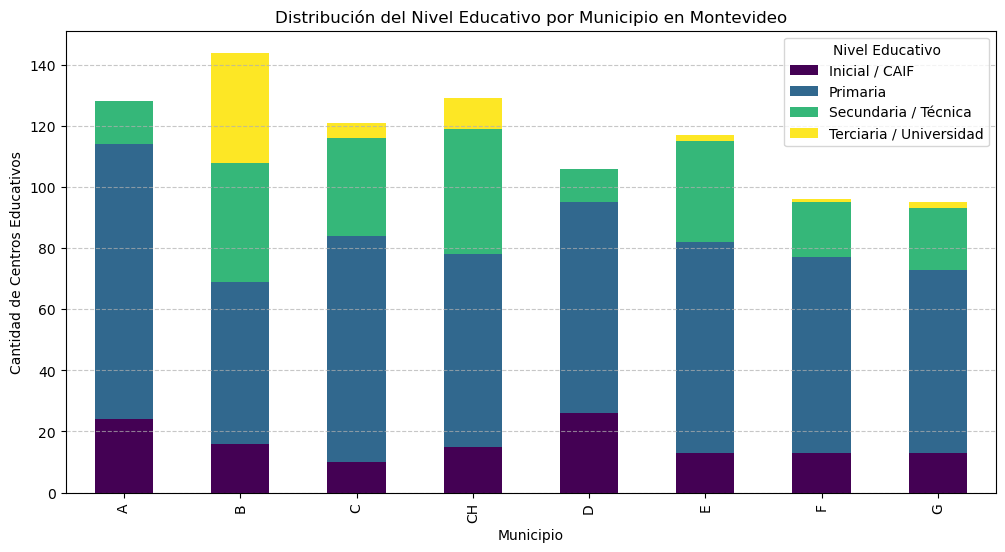

nivel_educativo  Inicial / CAIF  Otro  Primaria  Secundaria / Técnica  \
MUNICIPIO                                                               
A                            24     1        90                    14   
B                            16    15        53                    39   
C                            10    12        74                    32   
CH                           15     5        63                    41   
D                            26     1        69                    11   
E                            13     2        69                    33   
F                            13     3        64                    18   
G                            13     0        60                    20   

nivel_educativo  Terciaria / Universidad  
MUNICIPIO                                 
A                                      0  
B                                     36  
C                                      5  
CH                                    10  
D          

In [42]:
#Columna de nivel educativo
condiciones = [
    educacion_final['nombre'].str.contains('CAIF|C.A.I.F|Jardín|Jardin|Inicial', case=False, na=False),
    educacion_final['nombre'].str.contains('Escuela|Esc.|Colegio', case=False, na=False),
    educacion_final['nombre'].str.contains('Liceo|UTU|Instituto', case=False, na=False),
    educacion_final['nombre'].str.contains('Universidad|Facultad|Udelar|ORT|UCU|UM|UDE', case=False, na=False)
]
categorias = ['Inicial / CAIF', 'Primaria', 'Secundaria / Técnica', 'Terciaria / Universidad']
educacion_final['nivel_educativo'] = np.select(condiciones, categorias, default='Otro')
print(educacion_final['nivel_educativo'].value_counts())

distribucion_niveles = pd.crosstab(educacion_final['MUNICIPIO'], educacion_final['nivel_educativo'])
pd.crosstab(
    educacion_final['MUNICIPIO'], 
    educacion_final['nivel_educativo']
)[['Inicial / CAIF', 'Primaria', 'Secundaria / Técnica', 'Terciaria / Universidad', 'Otro']]

#Grafico de barras por municipio
tabla = pd.crosstab(educacion_final['MUNICIPIO'], educacion_final['nivel_educativo'])
tabla[['Inicial / CAIF', 'Primaria', 'Secundaria / Técnica', 'Terciaria / Universidad']].plot(
    kind='bar', 
    stacked=True, 
    figsize=(12, 6),
    colormap='viridis'
)
plt.title('Distribución del Nivel Educativo por Municipio en Montevideo')
plt.xlabel('Municipio')
plt.ylabel('Cantidad de Centros Educativos')
plt.legend(title='Nivel Educativo')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

tabla_resumen_educacion = pd.crosstab(educacion_final['MUNICIPIO'], educacion_final['nivel_educativo'])

print(tabla_resumen_educacion)

**3.Población**

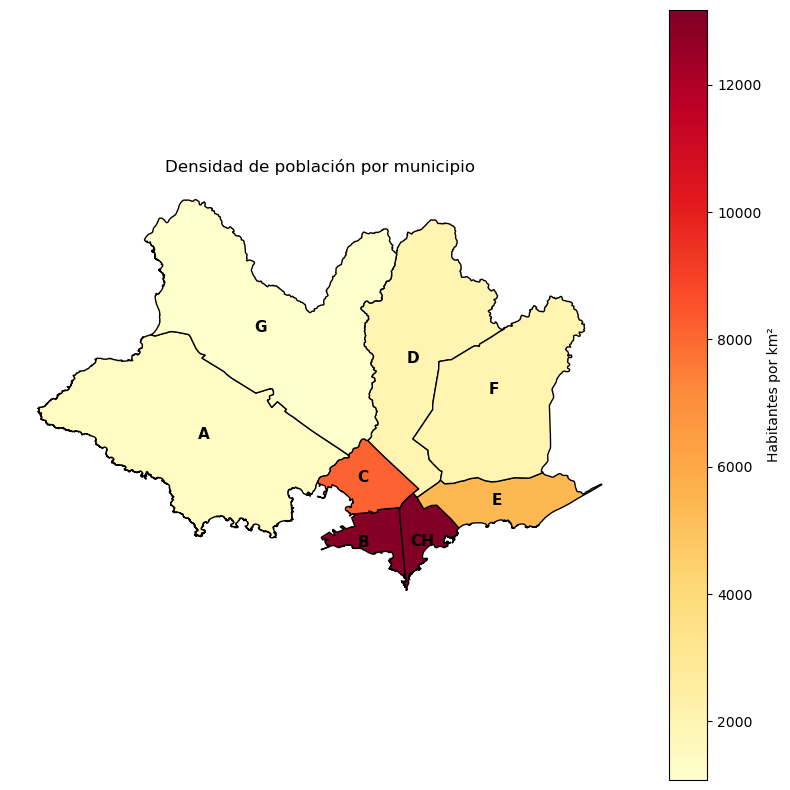

In [43]:
fig, ax = plt.subplots(figsize=(10, 10))

municipios.plot(
    column="habitantes_por_km2",
    cmap="YlOrRd",
    legend=True,
    edgecolor="black",
    ax=ax,
    legend_kwds={
        "label": "Habitantes por km²"
    }
)

# Letras de cada municipio
for _, row in municipios.iterrows():
    punto = row.geometry.representative_point()

    ax.text(
        punto.x,
        punto.y,
        row["MUNICIPIO"],
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="black"
    )

ax.set_title("Densidad de población por municipio")
ax.axis("off")

plt.show()

In [44]:
# ASIGNAR MUNICIPIO A CADA PUNTO

policlinicas_mun = gpd.sjoin(
    gdf_policlinicas,
    municipios[["MUNICIPIO", "geometry"]],
    how="left",
    predicate="within"
)

educacion_mun = gpd.sjoin(
    gdf_educacion,
    municipios[["MUNICIPIO", "geometry"]],
    how="left",
    predicate="within"
)

paradas_mun = gpd.sjoin(
    paradas,
    municipios[["MUNICIPIO", "geometry"]],
    how="left",
    predicate="within"
)

In [45]:
conteo_policlinicas = (
    policlinicas_mun
    .groupby("MUNICIPIO")
    .size()
    .reset_index(name="policlinicas")
)

conteo_educacion = (
    educacion_mun
    .groupby("MUNICIPIO")
    .size()
    .reset_index(name="centros_educativos")
)

conteo_paradas = (
    paradas_mun
    .groupby("MUNICIPIO")
    .size()
    .reset_index(name="paradas")
)

In [46]:
analisis_poblacion = municipios[
    ["MUNICIPIO", "poblacion", "area_km2", "habitantes_por_km2"]
].copy()

analisis_poblacion = analisis_poblacion.merge(
    conteo_policlinicas,
    on="MUNICIPIO",
    how="left"
)

analisis_poblacion = analisis_poblacion.merge(
    conteo_educacion,
    on="MUNICIPIO",
    how="left"
)

analisis_poblacion = analisis_poblacion.merge(
    conteo_paradas,
    on="MUNICIPIO",
    how="left"
)

In [47]:
analisis_poblacion[
    ["policlinicas", "centros_educativos", "paradas"]
] = analisis_poblacion[
    ["policlinicas", "centros_educativos", "paradas"]
].fillna(0)

In [48]:
# HABITANTES POR SERVICIO

analisis_poblacion["hab_por_policlinica"] = (
    analisis_poblacion["poblacion"]
    / analisis_poblacion["policlinicas"]
)

analisis_poblacion["hab_por_centro_educativo"] = (
    analisis_poblacion["poblacion"]
    / analisis_poblacion["centros_educativos"]
)

analisis_poblacion["hab_por_parada"] = (
    analisis_poblacion["poblacion"]
    / analisis_poblacion["paradas"]
)

In [49]:
# SERVICIOS POR CADA 10.000 HABITANTES

analisis_poblacion["policlinicas_10000_hab"] = (
    analisis_poblacion["policlinicas"]
    / analisis_poblacion["poblacion"]
    * 10000
)

analisis_poblacion["educacion_10000_hab"] = (
    analisis_poblacion["centros_educativos"]
    / analisis_poblacion["poblacion"]
    * 10000
)

analisis_poblacion["paradas_10000_hab"] = (
    analisis_poblacion["paradas"]
    / analisis_poblacion["poblacion"]
    * 10000
)

In [50]:
columnas_redondear = [
    "habitantes_por_km2",
    "hab_por_policlinica",
    "hab_por_centro_educativo",
    "hab_por_parada",
    "policlinicas_10000_hab",
    "educacion_10000_hab",
    "paradas_10000_hab"
]

analisis_poblacion[columnas_redondear] = (
    analisis_poblacion[columnas_redondear].round(2)
)

In [51]:
print(
    analisis_poblacion[
        [
            "MUNICIPIO",
            "poblacion",
            "habitantes_por_km2",
            "policlinicas",
            "hab_por_policlinica",
            "centros_educativos",
            "hab_por_centro_educativo",
            "paradas",
            "hab_por_parada"
        ]
    ]
)

  MUNICIPIO  poblacion  habitantes_por_km2  policlinicas  hab_por_policlinica  \
0         A     206236              1434.0             7             29462.29   
1         B     149350             13014.0             2             74675.00   
2         C     141785              8138.0             2             70892.50   
3        CH     157410             13174.0             1            157410.00   
4         D     173170              2013.0             4             43292.50   
5         E     145492              5422.0             2             72746.00   
6         F     173991              2044.0             2             86995.50   
7         G     153928              1081.0             3             51309.33   

   centros_educativos  hab_por_centro_educativo  paradas  hab_por_parada  
0                 129                   1598.73     8939           23.07  
1                 159                    939.31     6572           22.73  
2                 133                   1066.

**CRUCE DE DATOS CON VARIABLES SOCIOECONÓMICAS**

In [52]:
#nuevos dataframe para analizar
cob_salud = pd.read_excel(
    buscar_archivo("cobertura_salud.xlsx"),
)

economia = pd.read_csv(
    buscar_archivo("socioeconomia.csv"),
)

pob_ed = pd.read_csv(
    buscar_archivo("poblacion_educativa.csv")
)

movilidad = pd.read_csv(
    buscar_archivo("movilidad.csv")
)

edades = pd.read_csv(
    buscar_archivo("edades.csv")
)

print(economia.head(10))

  municipio  pobreza_0_a_4  pobreza_5_a_12  pobreza_13_a_60  pobreza_60_mas  \
0         A           44.0            33.5             21.4             6.9   
1         B            6.0             2.5              2.6             1.2   
2         C            5.3             5.8              3.7             0.8   
3        CH            0.0             3.4              1.4             0.8   
4         D           44.6            36.8             22.7            11.3   
5         E            9.2            10.0              4.7             1.5   
6         F           38.2            37.7             20.6             6.2   
7         G           27.8            30.0             16.9             5.2   

   pobreza_personas_total  pobreza_hogares  ta_hombre  ta_mujer  ta_total  \
0                    21.1             15.4       66.2      53.3      59.5   
1                     2.5              1.8       75.7      64.9      70.1   
2                     3.3              2.4       71.8    

Cruce: salud con cobertura salud y socioeconomia

In [53]:
conteo = salud_final.groupby("MUNICIPIO").size().reset_index(name="n_salud")

base = (
    economia.merge(cob_salud, on="municipio")
    .merge(conteo, left_on="municipio", right_on="MUNICIPIO", how="left")
    .drop(
        columns=["MUNICIPIO"]
    )
)

print(base)


  municipio  pobreza_0_a_4  pobreza_5_a_12  pobreza_13_a_60  pobreza_60_mas  \
0         A           44.0            33.5             21.4             6.9   
1         B            6.0             2.5              2.6             1.2   
2         C            5.3             5.8              3.7             0.8   
3        CH            0.0             3.4              1.4             0.8   
4         D           44.6            36.8             22.7            11.3   
5         E            9.2            10.0              4.7             1.5   
6         F           38.2            37.7             20.6             6.2   
7         G           27.8            30.0             16.9             5.2   

   pobreza_personas_total  pobreza_hogares  ta_hombre  ta_mujer  ta_total  \
0                    21.1             15.4       66.2      53.3      59.5   
1                     2.5              1.8       75.7      64.9      70.1   
2                     3.3              2.4       71.8    

In [54]:
pob = edades.groupby("municipio")["total"].sum().reset_index(name="pob_total")

base = base.merge(pob, on="municipio")
base["salud_x10mil"] = base["n_salud"] / base["pob_total"] * 10000

print(base[["municipio", "n_salud", "pob_total", "salud_x10mil"]])

  municipio  n_salud  pob_total  salud_x10mil
0         A       42     206236      2.036502
1         B       18     149351      1.205215
2         C       15     141782      1.057962
3        CH       33     157408      2.096463
4         D       23     173171      1.328167
5         E       23     145488      1.580886
6         F       20     173988      1.149505
7         G       17     153927      1.104420


In [55]:
conteo_educ = educacion_final.groupby("MUNICIPIO").size().reset_index(name="n_educ")
conteo_educ = (
    educacion_final.groupby("MUNICIPIO")
    .size()
    .reset_index(name="n_educ") 
)
# población de 0 a 19 años
jovenes = edades[edades["rango_edad"].isin(["pob_0_a_4", "pob_5_a_9", "pob_10_a_14", "pob_15_a_19"])]
pob_joven = jovenes.groupby("municipio")["total"].sum().reset_index(name="pob_0_19")

base.columns = base.columns.str.lower()
conteo_educ.columns = conteo_educ.columns.str.lower()
pob_joven.columns = pob_joven.columns.str.lower()

base = base.merge(conteo_educ, on="municipio").merge(
    pob_joven, on="municipio", how="left"
)

base["n_educ"] = base["n_educ"].fillna(0)

base["educ_x1000"] = base["n_educ"] / base["pob_0_19"] * 1000

cols = ["municipio", "pobreza_personas_total", "td_total", "cob_publica",
        "salud_x10mil", "educ_x1000"]
print(base[cols].round(1).sort_values("pobreza_personas_total", ascending=False))
print(base[cols[1:]].corr(method="spearman").round(2))

  municipio  pobreza_personas_total  td_total  cob_publica  salud_x10mil  \
4         D                    23.5      11.1         39.8           1.3   
0         A                    21.1      11.6         35.5           2.0   
6         F                    20.7      11.6         37.9           1.1   
7         G                    16.1       9.8         31.0           1.1   
5         E                     4.6       6.7         11.1           1.6   
2         C                     3.3       5.9         12.8           1.1   
1         B                     2.5       5.2         13.1           1.2   
3        CH                     1.4       5.4          4.3           2.1   

   educ_x1000  
4         2.2  
0         2.3  
6         2.0  
7         2.3  
5         3.8  
2         4.6  
1         6.6  
3         4.8  
                        pobreza_personas_total  td_total  cob_publica  \
pobreza_personas_total                    1.00      0.90         0.88   
td_total                 

In [57]:
base["pct_0_19"] = base["pob_0_19"] / base["pob_total"] * 100
base["educ_x1000_pobtotal"] = base["n_educ"] / base["pob_total"] * 1000

print(base[["municipio", "n_salud", "n_educ", "pob_total", "pob_0_19",
            "pct_0_19", "educ_x1000", "educ_x1000_pobtotal"]].round(1))
base["grupo"] = np.where(base["pobreza_personas_total"] > 15,
                         "Pobreza alta (A, D, F, G)", "Pobreza baja (B, C, CH, E)")

g = base.groupby("grupo").agg(n_salud=("n_salud", "sum"), n_educ=("n_educ", "sum"),
                              pob_total=("pob_total", "sum"), pob_0_19=("pob_0_19", "sum"))
g["salud_x10mil"] = g["n_salud"] / g["pob_total"] * 10000
g["educ_x1000"] = g["n_educ"] / g["pob_0_19"] * 1000
print(g.round(1))

  municipio  n_salud  n_educ  pob_total  pob_0_19  pct_0_19  educ_x1000  \
0         A       42     129     206236     57030      27.7         2.3   
1         B       18     159     149351     24187      16.2         6.6   
2         C       15     133     141782     28841      20.3         4.6   
3        CH       33     134     157408     27863      17.7         4.8   
4         D       23     107     173171     48332      27.9         2.2   
5         E       23     119     145488     30913      21.2         3.8   
6         F       20      99     173988     50072      28.8         2.0   
7         G       17      95     153927     40788      26.5         2.3   

   educ_x1000_pobtotal  
0                  0.6  
1                  1.1  
2                  0.9  
3                  0.9  
4                  0.6  
5                  0.8  
6                  0.6  
7                  0.6  
                            n_salud  n_educ  pob_total  pob_0_19  \
grupo                          

GRAFICOS

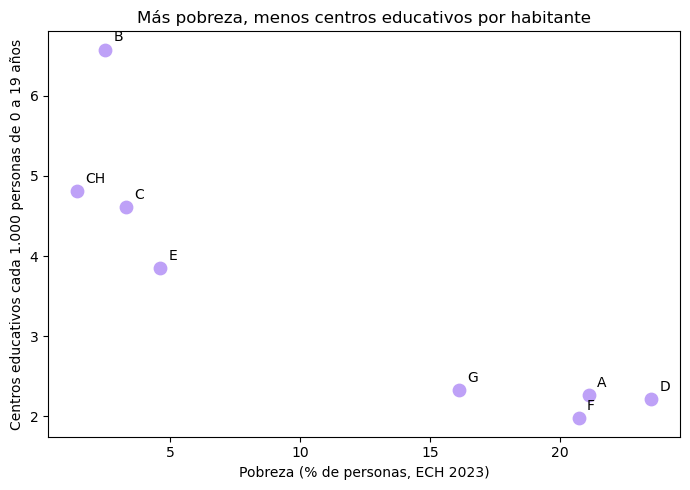

In [84]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(base["pobreza_personas_total"], base["educ_x1000"], s=80, color ="#BEA1F7")

for _, f in base.iterrows():
    ax.annotate(f["municipio"], (f["pobreza_personas_total"], f["educ_x1000"]),
                xytext=(6, 6), textcoords="offset points")

ax.set_xlabel("Pobreza (% de personas, ECH 2023)")
ax.set_ylabel("Centros educativos cada 1.000 personas de 0 a 19 años")
ax.set_title("Más pobreza, menos centros educativos por habitante")
plt.tight_layout()
fig.savefig("grafico_mas_pobreza_menos_centros.png", dpi=300, bbox_inches="tight")
plt.show()

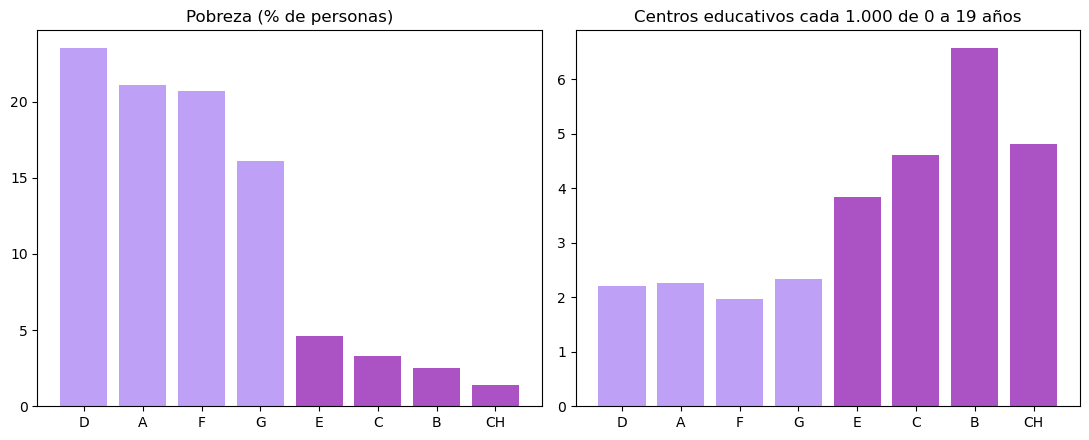

In [85]:
orden = base.sort_values("pobreza_personas_total", ascending=False)
colores = ["#BEA1F7" if p > 15 else "#AB52C5" for p in orden["pobreza_personas_total"]]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(orden["municipio"], orden["pobreza_personas_total"], color=colores)
axes[0].set_title("Pobreza (% de personas)")
axes[1].bar(orden["municipio"], orden["educ_x1000"], color=colores)
axes[1].set_title("Centros educativos cada 1.000 de 0 a 19 años")
plt.tight_layout()
fig.savefig("grafico_pobreza_y_centros_educativos", dpi=300, bbox_inches="tight")
plt.show()

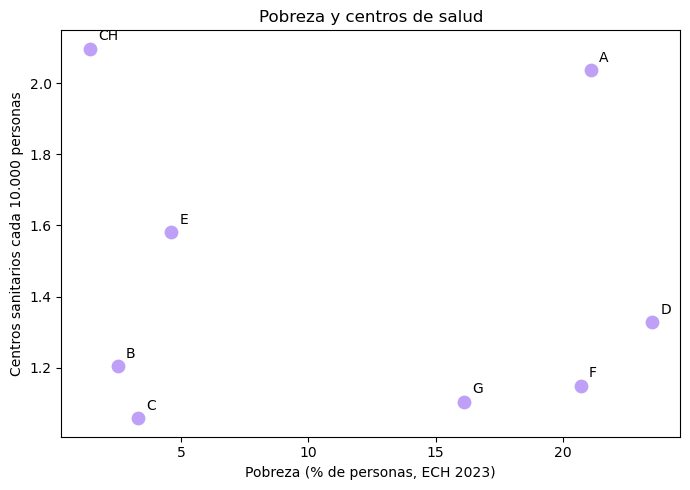

In [82]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(base["pobreza_personas_total"], base["salud_x10mil"], s=80, color ="#BEA1F7")

for _, f in base.iterrows():
    ax.annotate(f["municipio"], (f["pobreza_personas_total"], f["salud_x10mil"]),
                xytext=(6, 6), textcoords="offset points")

ax.set_xlabel("Pobreza (% de personas, ECH 2023)")
ax.set_ylabel("Centros sanitarios cada 10.000 personas")
ax.set_title("Pobreza y centros de salud")
plt.tight_layout()
fig.savefig("grafico_pobreza_centros_de_salud.png", dpi=300, bbox_inches="tight")
plt.show()

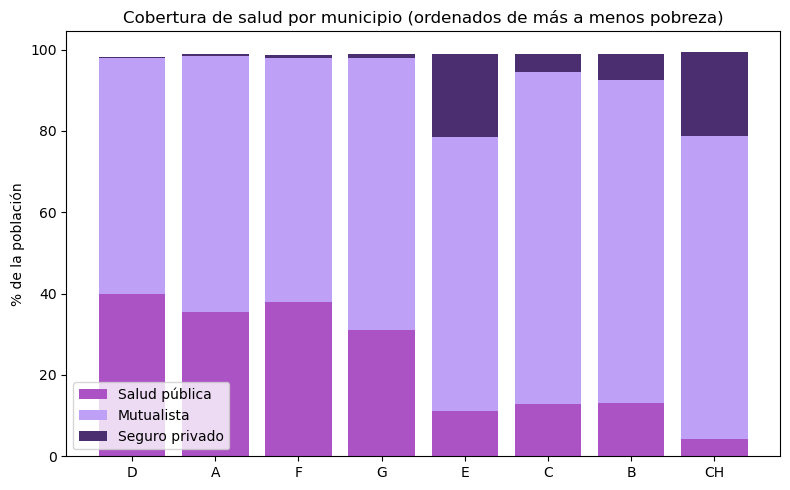

In [79]:
orden = base.sort_values("pobreza_personas_total", ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(orden["municipio"], orden["cob_publica"], label="Salud pública", color = "#AB52C5")
ax.bar(orden["municipio"], orden["cob_mutualista"],
       bottom=orden["cob_publica"], label="Mutualista", color ="#BEA1F7")
ax.bar(orden["municipio"], orden["cob_seguro_privado"],
       bottom=orden["cob_publica"] + orden["cob_mutualista"], label="Seguro privado", color="#4A2E6F")
ax.set_ylabel("% de la población")
ax.set_title("Cobertura de salud por municipio (ordenados de más a menos pobreza)")
ax.legend()
plt.tight_layout()
fig.savefig("grafico_cobertura_salud.png", dpi=300, bbox_inches="tight")
plt.show()

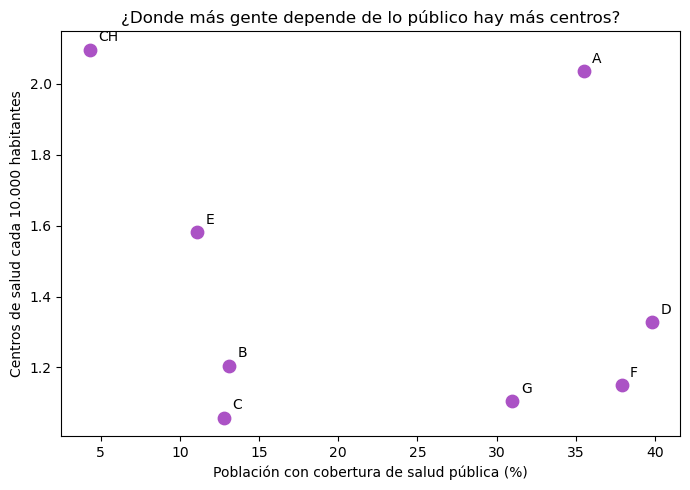

In [78]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(base["cob_publica"], base["salud_x10mil"], s=80, color = "#AB52C5")
for _, f in base.iterrows():
    ax.annotate(f["municipio"], (f["cob_publica"], f["salud_x10mil"]),
                xytext=(6, 6), textcoords="offset points")
ax.set_xlabel("Población con cobertura de salud pública (%)")
ax.set_ylabel("Centros de salud cada 10.000 habitantes")
ax.set_title("¿Donde más gente depende de lo público hay más centros?")
plt.tight_layout()
plt.show()
fig.savefig("grafico_dep_centros_publicos.png", dpi=300, bbox_inches="tight")

In [76]:
base["pob_dep_publica"] = (base["pob_total"] * base["cob_publica"] / 100).round()
print(base[["municipio", "pob_dep_publica"]].sort_values("pob_dep_publica", ascending=False))

  municipio  pob_dep_publica
0         A          73214.0
4         D          68922.0
6         F          65941.0
7         G          47717.0
1         B          19565.0
2         C          18148.0
5         E          16149.0
3        CH           6769.0


In [87]:
print(pob_ed.head(10))

  municipio tramo_edad  poblacion_total  asistencia_estimada_pct  \
0         A      4_a_5      5011.375388                   0.9670   
1         A     6_a_11     18740.286299                   0.9780   
2         A    12_a_14      9377.319588                   0.9700   
3         A    15_a_17      9310.383120                   0.9005   
4         A    18_a_25     24357.142857                   0.3360   
5         A        26+    131477.272727                   0.0440   
6         B      4_a_5      2203.742204                   0.9620   
7         B     6_a_11      6917.012448                   0.9640   
8         B    12_a_14      3230.200634                   0.9470   
9         B    15_a_17      3535.991141                   0.9030   

   demanda_efectiva  dato_estimado  anio_referencia  fuente  
0              4846          False              NaN     NaN  
1             18328          False              NaN     NaN  
2              9096          False              NaN     NaN  
3  

In [94]:
pob_ed["municipio"] = pob_ed["municipio"].str.upper().str.strip()

# Demanda de educación básica (4 a 17 años) y tasa de centros por 1.000 alumnos
basica = pob_ed[pob_ed["tramo_edad"].isin(["4_a_5", "6_a_11", "12_a_14", "15_a_17"])]
dem = basica.groupby("municipio")["demanda_efectiva"].sum().reset_index(name="demanda_4_17")
base = base.merge(dem, on="municipio", validate="1:1")
base["educ_x1000_alumnos"] = base["n_educ"] / base["demanda_4_17"] * 1000

# Asistencia a los 18-25 años
asist = (pob_ed.pivot(index="municipio", columns="tramo_edad", values="asistencia_estimada_pct")["18_a_25"]
           .rename("asist_18_25").reset_index())
base = base.merge(asist, on="municipio", validate="1:1")

Spearman: -0.88


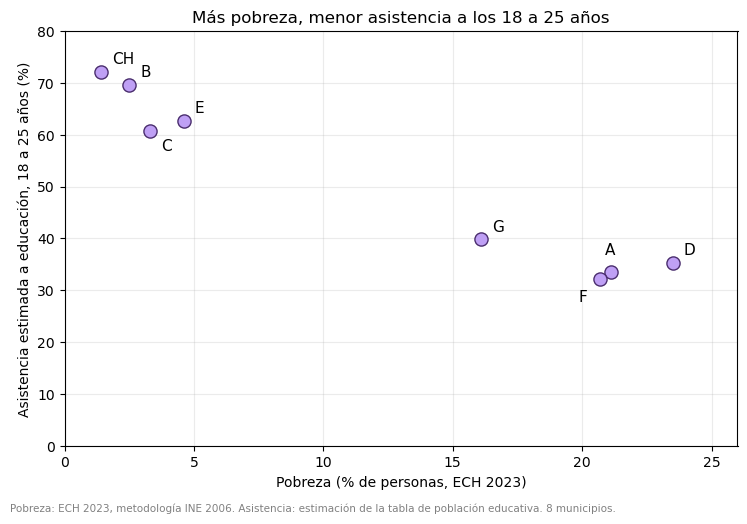

In [95]:
d = base[["municipio", "pobreza_personas_total", "asist_18_25"]].copy()
d["asist_pct"] = d["asist_18_25"] * 100

print("Spearman:", round(d["pobreza_personas_total"].corr(d["asist_pct"], method="spearman"), 2))

fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.scatter(d["pobreza_personas_total"], d["asist_pct"],
           s=90, color="#BFA0F5", edgecolor="#4A2E6E", zorder=3)

# Desplazamiento de las etiquetas (A, D y F quedan muy juntos y se pisarían)
off = {"D": (8, 6), "A": (-4, 12), "F": (-16, -16), "G": (8, 6),
       "E": (8, 6), "C": (8, -14), "B": (8, 6), "CH": (8, 6)}

for _, f in d.iterrows():
    ax.annotate(f["municipio"], (f["pobreza_personas_total"], f["asist_pct"]),
                xytext=off.get(f["municipio"], (8, 6)), textcoords="offset points", fontsize=11)

ax.set_xlabel("Pobreza (% de personas, ECH 2023)")
ax.set_ylabel("Asistencia estimada a educación, 18 a 25 años (%)")
ax.set_title("Más pobreza, menor asistencia a los 18 a 25 años")
ax.set_ylim(0, 80)
ax.set_xlim(0, 26)
ax.grid(alpha=0.25, zorder=0)

fig.text(0.01, 0.005,
         "Pobreza: ECH 2023, metodología INE 2006. Asistencia: estimación de la tabla de población educativa. 8 municipios.",
         fontsize=7.5, color="gray")

plt.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig("asistencia_18_25_vs_pobreza.png", dpi=300, bbox_inches="tight")
plt.show()